# Solar generation and weather in Belgium: data analysis

This notebook joins two files and checks whether together they are good enough to build a forecasting model.

| File | What it holds | Source |
|---|---|---|
| `ods032.parquet` | Solar generation, Elia's forecasts and monitored capacity, every 15 minutes | Elia open data (ods032) |
| `weather_belgium.parquet` | Archived weather forecasts for 11 points, hourly | Open-Meteo Historical Forecast API |

**Sections**
1. Load the Elia data
2. Load and check the weather data
3. Join the two
4. How weather drives output
5. A first benchmark: naive baseline, simple weather model, Elia

Run the cells from top to bottom. Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path(".")                        # folder holding the parquet files
ELIA_FILE = DATA_DIR / "ods032.parquet"     # full history; use ods032_2026.parquet for 2026 only
WEATHER_FILE = DATA_DIR / "weather_belgium.parquet"

# chart style
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the Elia data

Three choices are made here:

- **Provinces only.** Flanders, Wallonia and Belgium are exact sums of the provinces, so keeping them would count the same output twice.
- **UTC.** Elia publishes in Belgian local time. Weather data is in UTC, so we convert before joining.
- **Hourly.** Weather is hourly, so the 15 minute values are averaged to hours. Open-Meteo's radiation at hour *T* is the average over the hour ending at *T*, so each Elia hour is labelled with its end time to match.

In [2]:
AGGREGATES = ["Belgium", "Flanders", "Wallonia"]
cols = ["datetime", "region", "measured", "dayahead11hforecast", "dayahead11hconfidence10",
        "dayahead11hconfidence90", "mostrecentforecast", "monitoredcapacity"]

elia15 = pd.read_parquet(ELIA_FILE, columns=cols)
elia15 = elia15[~elia15["region"].isin(AGGREGATES)].copy()
elia15["datetime_utc"] = pd.to_datetime(elia15["datetime"], utc=True)

print(f"15-min rows: {len(elia15):,}")
print(f"Period: {elia15['datetime_utc'].min()}  to  {elia15['datetime_utc'].max()}")
print(f"Areas: {sorted(elia15['region'].unique())}")

15-min rows: 2,340,140
Period: 2020-09-30 22:00:00+00:00  to  2026-10-25 22:45:00+00:00
Areas: ['Antwerp', 'Brussels', 'East-Flanders', 'Flemish-Brabant', 'Hainaut', 'Limburg', 'Liège', 'Luxembourg', 'Namur', 'Walloon-Brabant', 'West-Flanders']


In [3]:
# Missing values by year: where are the holes?
missing = (elia15.assign(year=elia15["datetime_utc"].dt.year)
           .groupby("year")[["measured", "dayahead11hforecast", "mostrecentforecast"]]
           .agg(lambda s: s.isna().mean() * 100))
missing.columns = ["measured missing %", "day-ahead missing %", "most recent missing %"]
missing["rows"] = elia15.groupby(elia15["datetime_utc"].dt.year).size()
missing

,measured missing %,day-ahead missing %,most recent missing %,rows
year,,,,
2020,0.00,1.09,0.00,97240
2021,0.00,1.64,0.00,385440
2022,0.13,0.00,0.00,385440
2023,0.87,0.27,0.00,385440
2024,0.82,0.00,0.00,386496
2025,0.00,0.00,0.00,385440
2026,0.00,0.00,0.00,314644


In [4]:
# Average to hourly. An hour is kept only if all four 15-min values are present.
value_cols = ["measured", "dayahead11hforecast", "dayahead11hconfidence10",
              "dayahead11hconfidence90", "mostrecentforecast", "monitoredcapacity"]
grouped = (elia15.set_index("datetime_utc").groupby("region")[value_cols]
           .resample("1h", label="right", closed="left"))
elia = grouped.mean()
elia = elia[grouped["measured"].count() == 4].reset_index()

elia["lf"] = elia["measured"] / elia["monitoredcapacity"]               # load factor, 0 to 1
elia["lf_elia_da"] = elia["dayahead11hforecast"] / elia["monitoredcapacity"]
print(f"Hourly rows: {len(elia):,}")
elia.head()

Hourly rows: 585,035


,region,datetime_utc,measured,dayahead11hforecast,dayahead11hconfidence10,dayahead11hconfidence90,mostrecentforecast,monitoredcapacity,lf,lf_elia_da
0,Antwerp,2020-09-30 23:00:00+00:00,0.00,0.00,NaN,NaN,0.00,770.94,0.00,0.00
1,Antwerp,2020-10-01 00:00:00+00:00,0.00,0.00,NaN,NaN,0.00,770.94,0.00,0.00
2,Antwerp,2020-10-01 01:00:00+00:00,0.00,0.00,NaN,NaN,0.00,770.94,0.00,0.00
3,Antwerp,2020-10-01 02:00:00+00:00,0.00,0.00,NaN,NaN,0.00,770.94,0.00,0.00
4,Antwerp,2020-10-01 03:00:00+00:00,0.00,0.00,NaN,NaN,0.00,770.94,0.00,0.00


### Capacity over time

Monitored capacity is the denominator of the load factor. It grows a lot over the sample, and Elia updates it in steps, not continuously. Each step puts a small artificial jump into the load factor.

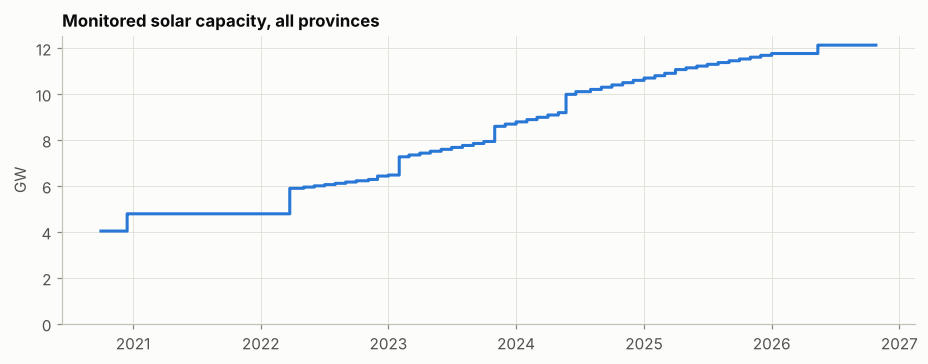

Capacity updates in the sample: 48
Growth over the sample: 4,037 MW to 12,128 MW (3.0x)


In [5]:
cap = elia.pivot(index="datetime_utc", columns="region", values="monitoredcapacity")
total = cap.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(total.index, total / 1000, color=BLUE, drawstyle="steps-post")
ax.set_title("Monitored solar capacity, all provinces")
ax.set_ylabel("GW")
ax.set_ylim(0)
plt.show()

steps = total[total.diff().abs() > 1]
print(f"Capacity updates in the sample: {len(steps)}")
print(f"Growth over the sample: {total.iloc[0]:,.0f} MW to {total.iloc[-1]:,.0f} MW "
      f"({total.iloc[-1] / total.iloc[0]:.1f}x)")

## 2. Load and check the weather data

Variables, one row per area per hour (UTC):

| Column | Meaning | Unit |
|---|---|---|
| `ghi_wm2` | Global horizontal irradiance (total sunlight on flat ground) | W/m² |
| `direct_wm2`, `diffuse_wm2` | Its two parts: straight from the sun, and scattered by sky and cloud | W/m² |
| `dni_wm2` | Direct irradiance on a surface facing the sun | W/m² |
| `cloud_*_pct` | Cloud cover: total, low, mid, high | % |
| `temp_c` | Air temperature at 2 m | °C |
| `wind_kmh` | Wind speed at 10 m | km/h |

In [6]:
wx = pd.read_parquet(WEATHER_FILE)
wx_cols = [c for c in wx.columns if c not in ("datetime_utc", "region", "latitude", "longitude")]

print(f"Rows: {len(wx):,}   Areas: {wx['region'].nunique()}")
print(f"Period: {wx['datetime_utc'].min()}  to  {wx['datetime_utc'].max()}")
print(f"Duplicate (area, hour) rows: {wx.duplicated(['region', 'datetime_utc']).sum()}")
expected = int((wx['datetime_utc'].max() - wx['datetime_utc'].min()) / pd.Timedelta('1h')) + 1
print(f"Hours per area: expected {expected:,}, found {wx.groupby('region').size().min():,} "
      f"to {wx.groupby('region').size().max():,}")
wx[wx_cols].describe().T[["count", "mean", "min", "max"]]

Rows: 560,736   Areas: 11
Period: 2021-01-01 00:00:00+00:00  to  2026-10-25 23:00:00+00:00
Duplicate (area, hour) rows: 0
Hours per area: expected 50,976, found 50,976 to 50,976


,count,mean,min,max
ghi_wm2,"560,736.00",135.17,0.00,930.00
direct_wm2,"560,736.00",77.25,0.00,820.00
diffuse_wm2,"560,736.00",57.92,0.00,443.00
dni_wm2,"560,736.00",147.50,0.00,948.80
cloud_total_pct,"560,736.00",67.65,0.00,100.00
cloud_low_pct,"560,736.00",37.82,0.00,100.00
cloud_mid_pct,"560,736.00",29.76,0.00,100.00
cloud_high_pct,"560,736.00",43.33,0.00,100.00
temp_c,"560,736.00",11.41,-11.80,39.50
wind_kmh,"560,736.00",12.97,0.00,71.40


In [7]:
# Missing weather values by year (% of rows)
(wx.assign(year=wx["datetime_utc"].dt.year).groupby("year")[wx_cols]
   .agg(lambda s: s.isna().mean() * 100))

,ghi_wm2,direct_wm2,diffuse_wm2,dni_wm2,cloud_total_pct,cloud_low_pct,cloud_mid_pct,cloud_high_pct,temp_c,wind_kmh
year,,,,,,,,,,
2021,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2022,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2023,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2024,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2025,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2026,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [8]:
# Sanity checks on the physics
night = wx[wx["datetime_utc"].dt.hour.isin([23, 0, 1])]
parts_gap = (wx["direct_wm2"] + wx["diffuse_wm2"] - wx["ghi_wm2"]).abs()
print(f"Irradiance above zero around midnight UTC: {(night['ghi_wm2'] > 0).mean():.2%} of rows")
print(f"Negative irradiance values: {(wx[['ghi_wm2', 'direct_wm2', 'diffuse_wm2']] < 0).sum().sum()}")
print(f"Direct + diffuse vs GHI: mean gap {parts_gap.mean():.2f} W/m², max gap {parts_gap.max():.1f} W/m²")
print(f"Highest GHI: {wx['ghi_wm2'].max():.0f} W/m² (clear summer noon in Belgium is roughly 850 to 950)")
print(f"Cloud cover outside 0 to 100: {((wx['cloud_total_pct'] < 0) | (wx['cloud_total_pct'] > 100)).sum()}")

Irradiance above zero around midnight UTC: 0.00% of rows
Negative irradiance values: 0
Direct + diffuse vs GHI: mean gap 0.00 W/m², max gap 0.1 W/m²
Highest GHI: 930 W/m² (clear summer noon in Belgium is roughly 850 to 950)
Cloud cover outside 0 to 100: 0


## 3. Join the two

An inner join on area and hour. Rows with a missing target or missing irradiance are dropped.

In [9]:
df = elia.merge(wx, on=["region", "datetime_utc"], how="inner")
before = len(df)
df = df.dropna(subset=["lf", "ghi_wm2"]).sort_values(["region", "datetime_utc"]).reset_index(drop=True)
df["year"] = df["datetime_utc"].dt.year
df["daylight"] = (df["ghi_wm2"] > 5) | (df["lf"] > 0.005)

print(f"Joined rows: {before:,}   after dropping missing: {len(df):,}")
print(f"Period: {df['datetime_utc'].min()}  to  {df['datetime_utc'].max()}")
print(f"Daylight rows: {df['daylight'].sum():,}")
df.groupby("year").agg(rows=("lf", "size"), daylight_rows=("daylight", "sum"),
                       mean_load_factor_pct=("lf", lambda s: s.mean() * 100))

Joined rows: 560,736   after dropping missing: 553,718
Period: 2021-01-01 00:00:00+00:00  to  2026-10-25 23:00:00+00:00
Daylight rows: 282,435


,rows,daylight_rows,mean_load_factor_pct
year,,,
2021,96360,48225,11.13
2022,95854,48290,12.51
2023,93016,48052,11.01
2024,93456,47797,9.84
2025,96360,48033,10.26
2026,78672,42038,12.46


### Impossible values

Output cannot exceed installed capacity, so a load factor above 100% signals a problem in the data. The usual cause is a capacity figure that had not yet been updated. These hours are listed and then removed.

In [10]:
bad = df[df["lf"] > 1]
print(f"Hours with load factor above 100%: {len(bad)}")
if len(bad):
    display(bad.groupby(["region", bad["datetime_utc"].dt.date]).agg(
        hours=("lf", "size"), max_load_factor_pct=("lf", lambda s: s.max() * 100),
        capacity_mw=("monitoredcapacity", "first"), max_measured_mw=("measured", "max")))
df = df[df["lf"] <= 1].reset_index(drop=True)
print(f"Rows kept: {len(df):,}")
print("Highest load factor by year (%):")
print((df.groupby("year")["lf"].max() * 100).round(1).to_string())

Hours with load factor above 100%: 23


hours  max_load_factor_pct  capacity_mw  \
region   datetime_utc                                            
Brussels 2022-03-21        5               146.55        54.59   
         2022-03-22        6               147.63        54.59   
         2022-03-23        6               148.44        54.59   
         2022-03-24        6               150.11        54.59   

                       max_measured_mw  
region   datetime_utc                   
Brussels 2022-03-21              80.00  
         2022-03-22              80.58  
         2022-03-23              81.03  
         2022-03-24              81.94

Rows kept: 553,695
Highest load factor by year (%):
year
2021   81.40
2022   96.10
2023   78.90
2024   78.60
2025   70.20
2026   75.40


## 4. How weather drives output

### 4.1 Irradiance against load factor

If the join is right, the points should fall along a rising line. A misaligned clock would show up as a wide loop.

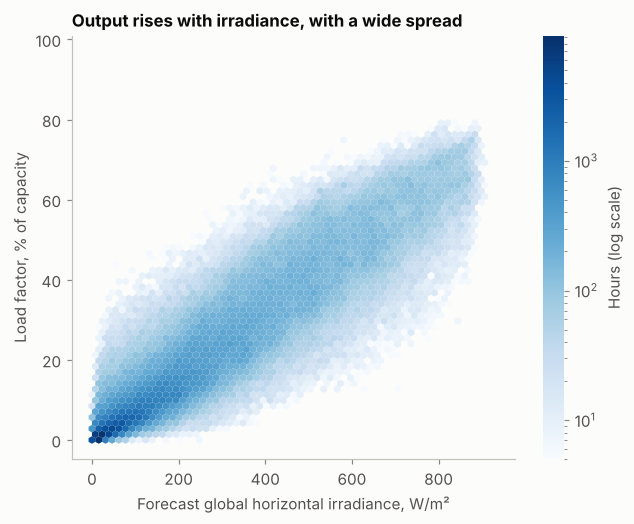

Correlation between GHI and load factor (daylight): 0.911


In [11]:
day = df[df["daylight"]]
fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(day["ghi_wm2"], day["lf"] * 100, gridsize=60, cmap="Blues", mincnt=5, bins="log", linewidths=0)
ax.set_xlabel("Forecast global horizontal irradiance, W/m²")
ax.set_ylabel("Load factor, % of capacity")
ax.set_title("Output rises with irradiance, with a wide spread")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax); cb.set_label("Hours (log scale)"); cb.outline.set_visible(False)
plt.show()
print(f"Correlation between GHI and load factor (daylight): {day['ghi_wm2'].corr(day['lf']):.3f}")

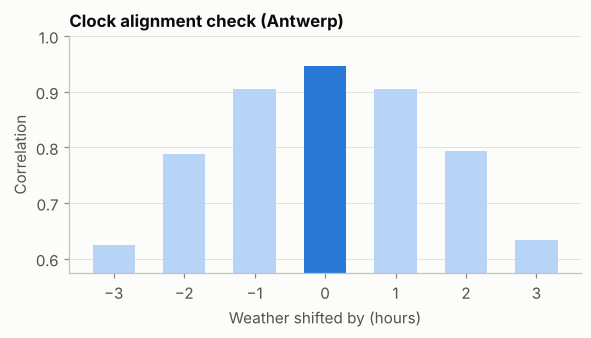

In [12]:
# Alignment test: shift the weather by a few hours and see where correlation peaks.
# It should peak at a shift of 0. A peak elsewhere means a time zone or labelling error.
one = df[df["region"] == "Antwerp"].set_index("datetime_utc")
shifts = range(-3, 4)
corr = [one["lf"].corr(one["ghi_wm2"].shift(s)) for s in shifts]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(list(shifts), corr, color=[BLUE if s == 0 else BLUE_LIGHT for s in shifts], width=0.6)
ax.set_ylim(min(corr) - 0.05, 1)
ax.set_xlabel("Weather shifted by (hours)"); ax.set_ylabel("Correlation")
ax.set_title("Clock alignment check (Antwerp)")
ax.grid(axis="x", visible=False)
plt.show()

### 4.2 Which variables carry information?

Correlation of each weather variable with load factor, daylight hours only. This is a first look, not a model: variables overlap a lot (irradiance already reflects cloud).

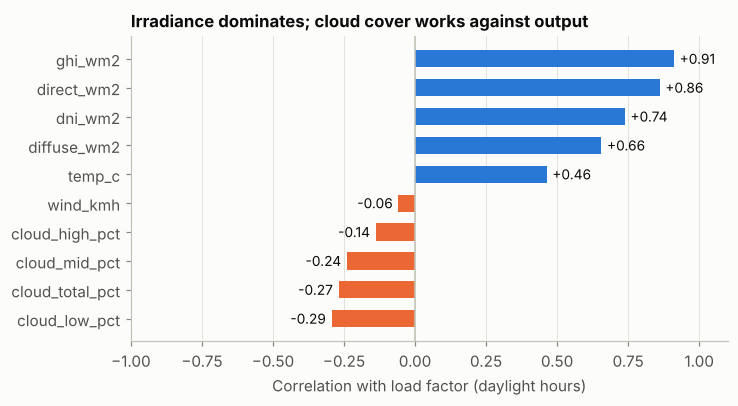

In [13]:
corr = day[wx_cols].corrwith(day["lf"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(corr.index, corr.values, color=[BLUE if v >= 0 else ORANGE for v in corr.values], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
for y, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=INK)
ax.set_xlim(-1, 1.1)
ax.set_xlabel("Correlation with load factor (daylight hours)")
ax.set_title("Irradiance dominates; cloud cover works against output")
ax.grid(axis="y", visible=False)
plt.show()

### 4.3 The cloud effect

To see cloud on its own we hold the sun's position roughly fixed: summer months, around midday (10:00 to 13:00 UTC).

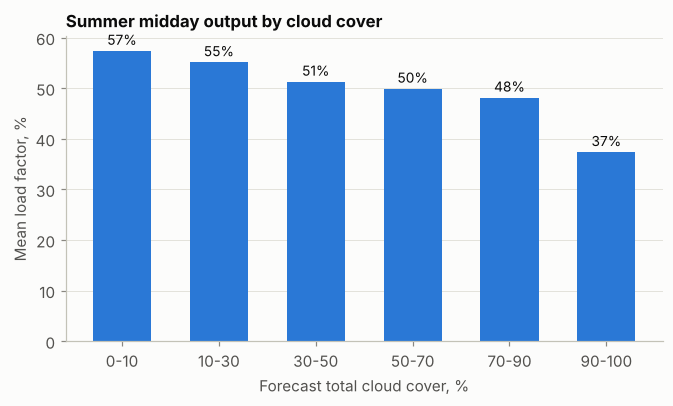

,mean load factor %,spread (std) %,hours
cloud_bin,,,
0-10,57.39,11.39,6119
10-30,55.14,12.66,2459
30-50,51.29,12.91,2626
50-70,49.91,13.70,2462
70-90,48.14,14.25,2829
90-100,37.38,16.37,15977


In [14]:
mid = df[df["datetime_utc"].dt.month.isin([5, 6, 7, 8]) & df["datetime_utc"].dt.hour.isin([10, 11, 12, 13])].copy()
mid["cloud_bin"] = pd.cut(mid["cloud_total_pct"], bins=[-1, 10, 30, 50, 70, 90, 100],
                          labels=["0-10", "10-30", "30-50", "50-70", "70-90", "90-100"])
g = mid.groupby("cloud_bin", observed=True)["lf"].agg(["mean", "std", "size"])

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m * 100 + 1.2, f"{m * 100:.0f}%", ha="center", fontsize=9, color=INK)
ax.set_xlabel("Forecast total cloud cover, %"); ax.set_ylabel("Mean load factor, %")
ax.set_title("Summer midday output by cloud cover")
ax.grid(axis="x", visible=False)
plt.show()
(g.assign(mean=g["mean"] * 100, std=g["std"] * 100)
  .rename(columns={"mean": "mean load factor %", "std": "spread (std) %", "size": "hours"}))

### 4.4 The temperature effect

Panels lose efficiency as they heat up. To isolate this we look at output per unit of sunlight (load factor divided by irradiance) on bright hours only, by temperature.

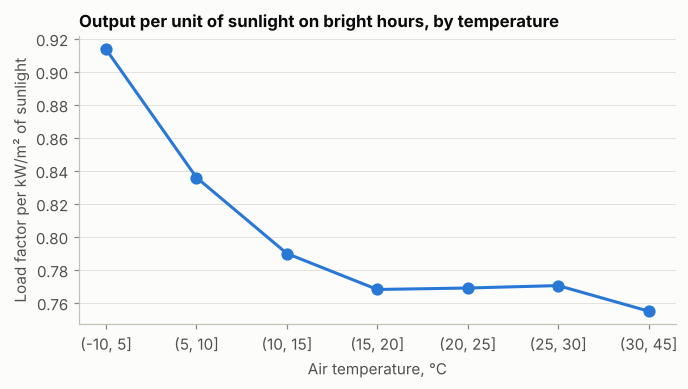

,yield,hours
temp_bin,,
"(-10, 5]",0.91,265
"(5, 10]",0.84,2482
"(10, 15]",0.79,7787
"(15, 20]",0.77,16041
"(20, 25]",0.77,17281
"(25, 30]",0.77,8193
"(30, 45]",0.75,1891


In [15]:
bright = df[df["ghi_wm2"] > 500].copy()
bright["yield_per_kwm2"] = bright["lf"] / (bright["ghi_wm2"] / 1000)
bright["temp_bin"] = pd.cut(bright["temp_c"], bins=[-10, 5, 10, 15, 20, 25, 30, 45])
t = bright.groupby("temp_bin", observed=True)["yield_per_kwm2"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(t.index.astype(str), t["mean"], color=BLUE, marker="o", markersize=7)
ax.set_xlabel("Air temperature, °C"); ax.set_ylabel("Load factor per kW/m² of sunlight")
ax.set_title("Output per unit of sunlight on bright hours, by temperature")
ax.grid(axis="x", visible=False)
plt.show()
t.rename(columns={"mean": "yield", "size": "hours"})

### 4.5 A typical day by season

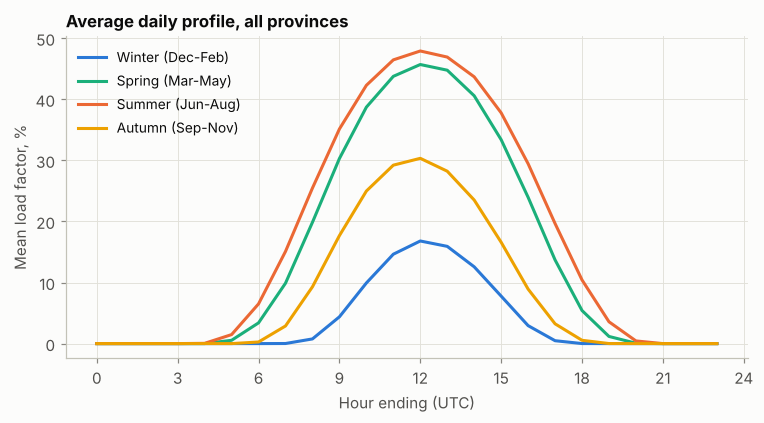

In [16]:
be = df.groupby("datetime_utc").agg(measured=("measured", "sum"), cap=("monitoredcapacity", "sum"))
be["lf"] = be["measured"] / be["cap"] * 100
be["hour"] = be.index.hour
seasons = {"Winter (Dec-Feb)": [12, 1, 2], "Spring (Mar-May)": [3, 4, 5],
           "Summer (Jun-Aug)": [6, 7, 8], "Autumn (Sep-Nov)": [9, 10, 11]}
fig, ax = plt.subplots(figsize=(8, 3.8))
for (name, months), color in zip(seasons.items(), [BLUE, AQUA, ORANGE, "#eda100"]):
    prof = be[be.index.month.isin(months)].groupby("hour")["lf"].mean()
    ax.plot(prof.index, prof.values, color=color, label=name)
ax.set_xlabel("Hour ending (UTC)"); ax.set_ylabel("Mean load factor, %")
ax.set_xticks(range(0, 25, 3))
ax.set_title("Average daily profile, all provinces")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 5. A first benchmark

Three forecasts of hourly load factor, compared on the same test period:

1. **Naive:** the same hour yesterday.
2. **Simple weather model:** a linear regression on irradiance and temperature, fitted by ordinary least squares on the training years. No machine learning library is needed.
3. **Elia:** the operator's day-ahead forecast issued at 11:00.

The split is by time: train before 2025, test on 2025 and 2026.

**Important caveat.** The weather file comes from Open-Meteo's archive, which stitches together each weather model run's first few hours. That makes it a very short-range forecast, more accurate than what was known at 11:00 the day before. So the simple model's score below is optimistic compared with a true day-ahead forecast. Treat it as an upper bound on what this weather source can give.

In [17]:
# Naive forecast: the load factor exactly 24 hours earlier (matched on the clock, so gaps cannot shift it)
prev = df[["region", "datetime_utc", "lf"]].rename(columns={"lf": "lf_naive"})
prev["datetime_utc"] = prev["datetime_utc"] + pd.Timedelta("24h")
df = df.drop(columns="lf_naive", errors="ignore").merge(prev, on=["region", "datetime_utc"], how="left")

features = ["ghi_wm2", "direct_wm2", "diffuse_wm2", "temp_c"]
model = df[df["daylight"]].dropna(subset=features + ["lf", "lf_naive", "lf_elia_da"]).copy()
model["ghi_x_temp"] = model["ghi_wm2"] * model["temp_c"]
X_cols = features + ["ghi_x_temp"]

train, test = model[model["year"] < 2025], model[model["year"] >= 2025].copy()
X = lambda d: np.column_stack([np.ones(len(d)), d[X_cols].to_numpy()])
beta, *_ = np.linalg.lstsq(X(train), train["lf"].to_numpy(), rcond=None)
test["lf_weather"] = np.clip(X(test) @ beta, 0, 1)

print(f"Train: {len(train):,} daylight hours, {train['datetime_utc'].min():%Y-%m} to {train['datetime_utc'].max():%Y-%m}")
print(f"Test:  {len(test):,} daylight hours, {test['datetime_utc'].min():%Y-%m} to {test['datetime_utc'].max():%Y-%m}")

def score(pred):
    err = (test[pred] - test["lf"]) * 100
    return {"nMAE %": err.abs().mean(), "nRMSE %": np.sqrt((err ** 2).mean()), "bias %": err.mean()}

results = pd.DataFrame({"Naive (same hour yesterday)": score("lf_naive"),
                        "Simple weather model": score("lf_weather"),
                        "Elia day-ahead (11:00)": score("lf_elia_da")}).T
results

Train: 191,359 daylight hours, 2021-01 to 2024-12
Test:  90,071 daylight hours, 2025-01 to 2026-10


,nMAE %,nRMSE %,bias %
Naive (same hour yesterday),7.86,12.10,-0.04
Simple weather model,6.28,8.79,1.49
Elia day-ahead (11:00),3.63,5.42,0.47


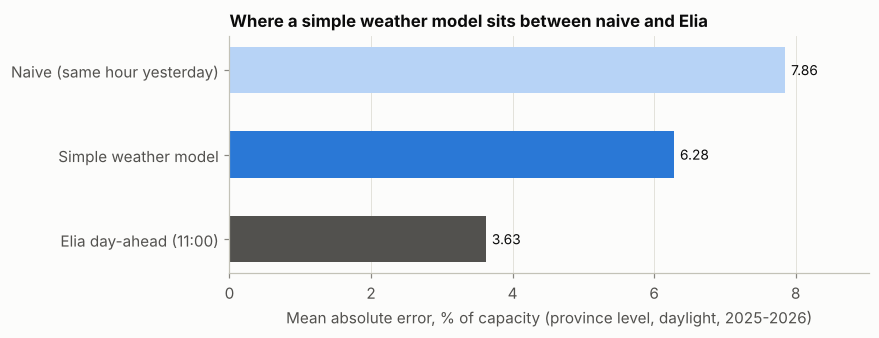

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
r = results["nMAE %"].iloc[::-1]
ax.barh(r.index, r.values, color=[INK2, BLUE, BLUE_LIGHT], height=0.55)
for y, v in enumerate(r.values):
    ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0, r.max() * 1.15)
ax.set_xlabel("Mean absolute error, % of capacity (province level, daylight, 2025-2026)")
ax.set_title("Where a simple weather model sits between naive and Elia")
ax.grid(axis="y", visible=False)
plt.show()

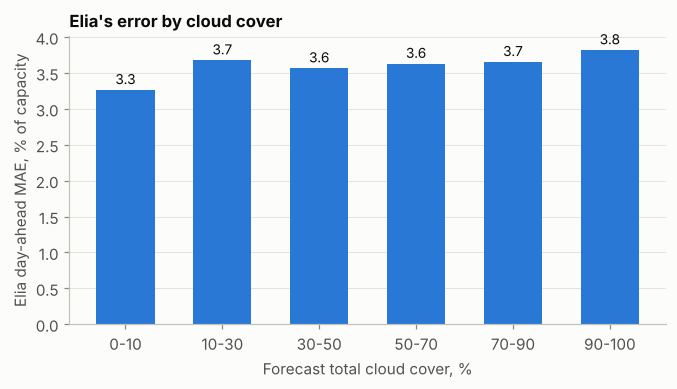

,bias,mae,hours
cloud_bin,,,
0-10,0.06,3.27,26378
10-30,0.17,3.68,4721
30-50,0.11,3.57,3210
50-70,0.13,3.63,3125
70-90,0.01,3.66,4700
90-100,0.81,3.82,47937


In [19]:
# Does weather explain Elia's remaining error? Elia's day-ahead error by forecast cloud cover.
test["elia_err"] = (test["lf_elia_da"] - test["lf"]) * 100
test["cloud_bin"] = pd.cut(test["cloud_total_pct"], bins=[-1, 10, 30, 50, 70, 90, 100],
                           labels=["0-10", "10-30", "30-50", "50-70", "70-90", "90-100"])
e = test.groupby("cloud_bin", observed=True)["elia_err"].agg(
    bias="mean", mae=lambda s: s.abs().mean(), hours="size")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(e.index.astype(str), e["mae"], color=BLUE, width=0.6)
for i, v in enumerate(e["mae"]):
    ax.text(i, v + 0.08, f"{v:.1f}", ha="center", fontsize=9, color=INK)
ax.set_xlabel("Forecast total cloud cover, %"); ax.set_ylabel("Elia day-ahead MAE, % of capacity")
ax.set_title("Elia's error by cloud cover")
ax.grid(axis="x", visible=False)
plt.show()
e

## What to take from this

Fill this in from the outputs above once you have run the notebook on the full history:

- **Is the join clean?** Section 3 row counts, and the alignment check in 4.1.
- **Does weather explain output?** The correlation in 4.1 and the cloud table in 4.3.
- **How much room is there?** The gap between the simple weather model and Elia in section 5.
- **Where is Elia weakest?** The cloud cover table at the end of section 5.

**Next steps**
1. Replace the linear model with gradient boosted trees and add solar elevation and clear-sky irradiance (pvlib).
2. Switch to quantile loss to produce P10 and P90, and compare calibration with Elia's bands.
3. For a true day-ahead test, download forecasts as issued the day before (Open-Meteo Single Runs API, ECMWF model, available from March 2024).